# 问题描述

使用Python/C/C++/等来编写一个能解决如下平面问题的有限元计算程序。

（1）输入文件：

本次作业不指定输入文件，但需要输入文件。

（2）输出文件：

本次作业输出文件内容如下：

|E (element number) |     Stress |  Strain|
|---|---|---|
|1 |                     xxx  |  xxx|
|2 |                     xxx  |  xxx|

|N(nodes number)    |  Displacement |  Force|
|---|---|---|
|1      |                 xxx     |   xxx|
|2           |            xxx    |    xxx|

（3）问题描述：

考虑下图所示平面应变条件下悬臂板的分析。其中L=1m，均布力F=100N/m

![](picture.png)

E= 200GPa，v=0.499

试编写有限元计算程序求解各个节点的位移、力、各单元的应力与应变。


# 前置处理

## 导入库

In [5]:
import numpy as np
import math
import matplotlib.pyplot as plt

## 从input.txt中读取输入信息

In [6]:
with open("../../input/Cantilever plate.txt", "r") as f:
    txt = f.readlines()
    L = float(txt[0].strip())
    F = float(txt[1].strip())
    E = float(txt[2].strip())
    v = float(txt[3].strip())
    t = float(txt[4].strip())
    nx = int(txt[5].strip())
    ny = int(txt[6].strip())

# 定义函数

In [7]:
# 平面应力材料属性矩阵[D]
def elastic_matrix(E, v):
    D = np.array([
        [1, v, 0],
        [v, 1, 0],
        [0, 0, (1 - v) / 2]
    ]) * (E / (1-v**2))
    return D

# 4节点四边形等参单元插值函数
def shape_functions(xi, eta):
    N = np.zeros(4)
    N[0] = 0.25 * (1 - xi) * (1 - eta)
    N[1] = 0.25 * (1 + xi) * (1 - eta)
    N[2] = 0.25 * (1 + xi) * (1 + eta)
    N[3] = 0.25 * (1 - xi) * (1 + eta)
    return N

# 插值函数对自然坐标的导数
def shape_derivatives(xi, eta):
    dN = np.zeros((4, 2))
    dN[0, 0] = -0.25 * (1 - eta)  # dN1/dxi
    dN[0, 1] = -0.25 * (1 - xi)   # dN1/deta
    dN[1, 0] =  0.25 * (1 - eta)  # dN2/dxi
    dN[1, 1] = -0.25 * (1 + xi)   # dN2/deta
    dN[2, 0] =  0.25 * (1 + eta)  # dN3/dxi
    dN[2, 1] =  0.25 * (1 + xi)   # dN3/deta
    dN[3, 0] = -0.25 * (1 + eta)  # dN4/dxi
    dN[3, 1] =  0.25 * (1 - xi)   # dN4/deta
    return dN

# 生成网格
def generate_mesh():
    nodes = []
    elements = []
    
    # 创建节点
    node_id = 0
    for j in range(ny + 1):
        for i in range(nx + 1):
            x = i * L / nx
            # 上边界倾斜：从(0,L)到(L, 0.75L)
            y_top = L - 0.25 * x
            y = j * y_top / ny
            nodes.append([x, y])
            node_id += 1
    
    # 创建单元
    elem_id = 0
    for j in range(ny):
        for i in range(nx):
            n1 = i + j * (nx + 1)
            n2 = i + 1 + j * (nx + 1)
            n3 = i + 1 + (j + 1) * (nx + 1)
            n4 = i + (j + 1) * (nx + 1)
            elements.append([n1, n2, n3, n4])
            elem_id += 1
    
    return np.array(nodes), np.array(elements)

# 计算单元刚度矩阵
def element_stiffness(nodes, D):
    # 2x2高斯积分点
    gauss_points = [
        [-1/math.sqrt(3), -1/math.sqrt(3)],
        [1/math.sqrt(3), -1/math.sqrt(3)],
        [1/math.sqrt(3), 1/math.sqrt(3)],
        [-1/math.sqrt(3), 1/math.sqrt(3)]
    ]
    weights = [1.0, 1.0, 1.0, 1.0]
    
    K_e = np.zeros((8, 8))
    
    for gp, w in zip(gauss_points, weights):
        xi, eta = gp
        dN = shape_derivatives(xi, eta)
        
        # 计算雅可比矩阵
        J = np.zeros((2, 2))
        for i in range(4):
            J[0, 0] += dN[i, 0] * nodes[i, 0]
            J[0, 1] += dN[i, 0] * nodes[i, 1]
            J[1, 0] += dN[i, 1] * nodes[i, 0]
            J[1, 1] += dN[i, 1] * nodes[i, 1]
        
        detJ = np.linalg.det(J)
        invJ = np.linalg.inv(J)
        
        # 计算插值函数对x,y的导数
        dN_dx = np.zeros(4)
        dN_dy = np.zeros(4)
        for i in range(4):
            dN_dx[i] = invJ[0, 0] * dN[i, 0] + invJ[0, 1] * dN[i, 1]
            dN_dy[i] = invJ[1, 0] * dN[i, 0] + invJ[1, 1] * dN[i, 1]
        
        # 构造B矩阵
        B = np.zeros((3, 8))
        for i in range(4):
            B[0, 2*i] = dN_dx[i]
            B[1, 2*i+1] = dN_dy[i]
            B[2, 2*i] = dN_dy[i]
            B[2, 2*i+1] = dN_dx[i]
        
        # 积分点贡献
        K_e += B.T @ D @ B * detJ * w * t
    
    return K_e

# 计算单元应力和应变
def element_stress_strain(nodes, D, displacements):
    # 使用单元中心点 (xi=0, eta=0)
    xi, eta = 0.0, 0.0
    dN = shape_derivatives(xi, eta)
    
    # 计算雅可比矩阵
    J = np.zeros((2, 2))
    for i in range(4):
        J[0, 0] += dN[i, 0] * nodes[i, 0]
        J[0, 1] += dN[i, 0] * nodes[i, 1]
        J[1, 0] += dN[i, 1] * nodes[i, 0]
        J[1, 1] += dN[i, 1] * nodes[i, 1]
    
    detJ = np.linalg.det(J)
    invJ = np.linalg.inv(J)
    
    # 计算形函数对x,y的导数
    dN_dx = np.zeros(4)
    dN_dy = np.zeros(4)
    for i in range(4):
        dN_dx[i] = invJ[0, 0] * dN[i, 0] + invJ[0, 1] * dN[i, 1]
        dN_dy[i] = invJ[1, 0] * dN[i, 0] + invJ[1, 1] * dN[i, 1]
    
    # 构造B矩阵
    B = np.zeros((3, 8))
    for i in range(4):
        B[0, 2*i] = dN_dx[i]
        B[1, 2*i+1] = dN_dy[i]
        B[2, 2*i] = dN_dy[i]
        B[2, 2*i+1] = dN_dx[i]
    
    # 提取单元位移
    disp_e = np.zeros(8)
    for i in range(4):
        node_index = nodes[i]  # 注意：这里nodes是坐标数组
        global_node = np.where((nodes == node_index).all(axis=1))[0][0]
        disp_e[2*i] = displacements[2*global_node]
        disp_e[2*i+1] = displacements[2*global_node+1]
    
    # 计算应变和应力
    strain = B @ disp_e
    stress = D @ strain
    
    return stress, strain

# 生成四边形网格

生成网格完成: 231 个节点, 200 个单元


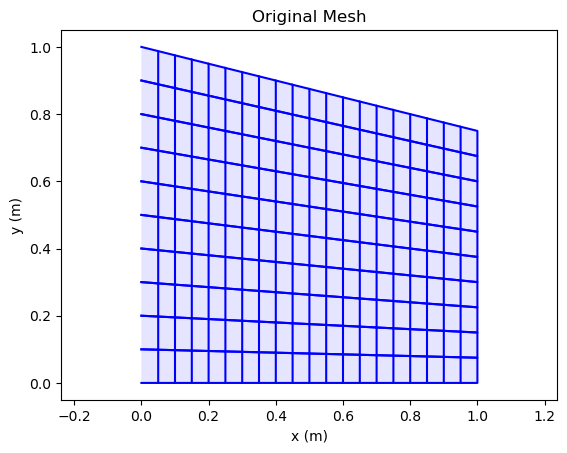

In [8]:
nodes, elements = generate_mesh()
num_nodes = len(nodes)
num_elements = len(elements)
print(f"生成网格完成: {num_nodes} 个节点, {num_elements} 个单元")

for elem in elements:
    poly = nodes[elem]
    plt.plot(poly[:, 0], poly[:, 1], 'b-')
    plt.fill(poly[:, 0], poly[:, 1], 'b', alpha=0.1)
plt.title("Original Mesh")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis('equal')
plt.savefig("../../output/Cantilever plate/Original Mesh.png")

# 求解计算

## 计算材料属性矩阵D

In [9]:
D = elastic_matrix(E, v)
print("材料矩阵计算完成")

材料矩阵计算完成


## 组装全局刚度矩阵

In [10]:
# 初始化全局刚度矩阵和载荷向量
K_global = np.zeros((2*num_nodes, 2*num_nodes))
F_global = np.zeros(2*num_nodes)

# 组装全局刚度矩阵
for elem_id, elem_nodes in enumerate(elements):
    elem_coords = nodes[elem_nodes]
    K_e = element_stiffness(elem_coords, D)
        
    # 将单元刚度矩阵组装到全局矩阵
    for i in range(4):
        for j in range(4):
            # 节点自由度索引
            i_idx = [2*elem_nodes[i], 2*elem_nodes[i]+1]
            j_idx = [2*elem_nodes[j], 2*elem_nodes[j]+1]
                
            # 组装2x2子矩阵
            for p in range(2):
                for q in range(2):
                    K_global[i_idx[p], j_idx[q]] += K_e[2*i+p, 2*j+q]
    
print("全局刚度矩阵组装完成")

全局刚度矩阵组装完成


## 边界条件处理

### 左端固定边界条件

In [11]:
fixed_nodes = [i for i in range(num_nodes) if nodes[i, 0] < 1e-6]
fixed_dofs = []
for node in fixed_nodes:
    fixed_dofs.append(2*node)    # x方向
    fixed_dofs.append(2*node+1)  # y方向
print(f"固定边界条件: {len(fixed_nodes)} 个节点")

固定边界条件: 11 个节点


### 上端均布载荷边界条件

In [12]:
top_nodes = []
for i in range(num_nodes):
    # 上边界节点 (y坐标接近上边界)
    y_top = L - 0.25 * nodes[i, 0]
    if abs(nodes[i, 1] - y_top) < 1e-6:
        top_nodes.append(i)
    
# 按x坐标排序
top_nodes.sort(key=lambda i: nodes[i, 0])
print(f"上边界节点数: {len(top_nodes)}")
    
# 计算每个上边界节点施加的力
total_length = 0
for i in range(len(top_nodes)-1):
    x1, y1 = nodes[top_nodes[i]]
    x2, y2 = nodes[top_nodes[i+1]]
    segment_length = math.sqrt((x2-x1)**2 + (y2-y1)**2)
    total_length += segment_length
    
# 施加节点力
for i in range(len(top_nodes)):
    # 找到相邻节点
    if i == 0:
        # 第一个节点
        x1, y1 = nodes[top_nodes[i]]
        x2, y2 = nodes[top_nodes[i+1]]
        segment_length = math.sqrt((x2-x1)**2 + (y2-y1)**2)
        force = F * segment_length / 2
    elif i == len(top_nodes)-1:
        # 最后一个节点
        x1, y1 = nodes[top_nodes[i-1]]
        x2, y2 = nodes[top_nodes[i]]
        segment_length = math.sqrt((x2-x1)**2 + (y2-y1)**2)
        force = F * segment_length / 2
    else:
        # 中间节点
        x1, y1 = nodes[top_nodes[i-1]]
        x2, y2 = nodes[top_nodes[i]]
        seg1_length = math.sqrt((x2-x1)**2 + (y2-y1)**2)
            
        x1, y1 = nodes[top_nodes[i]]
        x2, y2 = nodes[top_nodes[i+1]]
        seg2_length = math.sqrt((x2-x1)**2 + (y2-y1)**2)
            
        force = F * (seg1_length + seg2_length) / 2
        
    # 施加y方向力
    F_global[2*top_nodes[i]+1] += force
    
print(f"施加载荷完成, 总载荷: {np.sum(F_global[1::2]):.2f} N")

上边界节点数: 21
施加载荷完成, 总载荷: -103.08 N


## 求解控制方程

In [13]:
penalty = 1e20
for dof in fixed_dofs:
    K_global[dof, dof] += penalty

# 求解方程组
displacements = np.linalg.solve(K_global, F_global)
print("方程组求解完成")
    
# 提取节点位移
node_displacements = np.zeros((num_nodes, 2))
for i in range(num_nodes):
    node_displacements[i, 0] = displacements[2*i]     # u_x
    node_displacements[i, 1] = displacements[2*i+1]   # u_y
    
# 计算节点力
node_forces = K_global @ displacements
    
# 计算单元应力和应变
element_stresses = []
element_strains = []
for elem_id, elem_nodes in enumerate(elements):
    elem_coords = nodes[elem_nodes]
    stress, strain = element_stress_strain(elem_coords, D, displacements)
    element_stresses.append(stress)
    element_strains.append(strain)
print("单元应力和应变计算完成")

方程组求解完成
单元应力和应变计算完成


# 结果可视化

应力云图已保存到 ../../output/Cantilever plate/Stress Contour Diagram.png


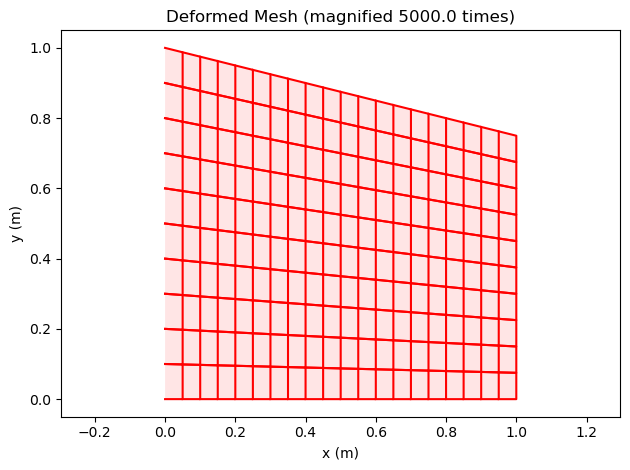

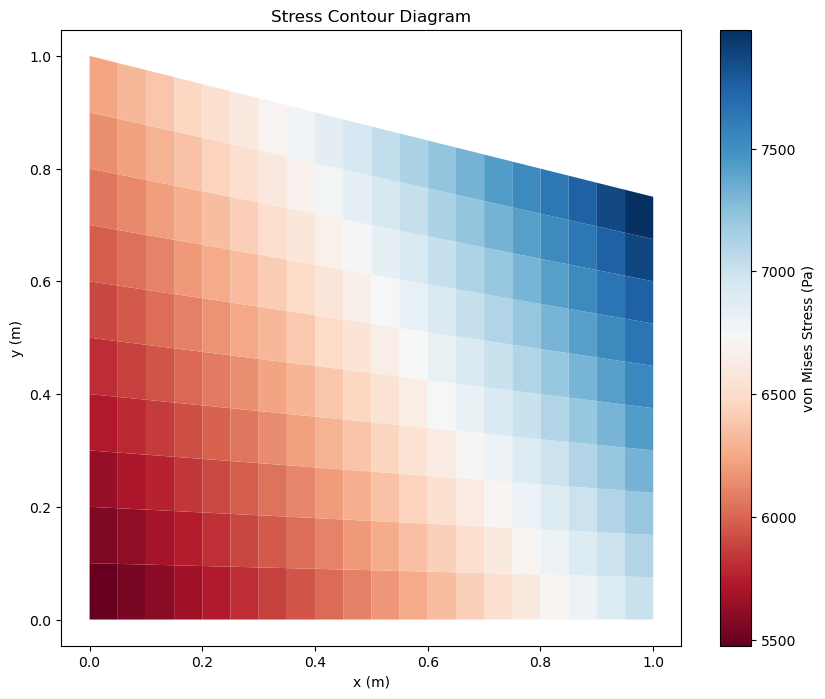

In [14]:
# 可视化变形
scale_factor = 5e3  # 位移放大系数
deformed_nodes = nodes + node_displacements * scale_factor
    
# 绘制变形网格
for elem in elements:
    poly = deformed_nodes[elem]
    plt.plot(poly[:, 0], poly[:, 1], 'r-')
    plt.fill(poly[:, 0], poly[:, 1], 'r', alpha=0.1)
plt.title(f"Deformed Mesh (magnified {scale_factor} times)")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis('equal')
    
plt.tight_layout()
plt.savefig("../../output/Cantilever plate/Deformed Mesh.png")

# 绘制应力云图
plt.figure(figsize=(10, 8))
    
# 计算每个单元的von Mises应力
von_mises_stress = []
for stress in element_stresses:
    sxx, syy, sxy = stress
    vm = math.sqrt(sxx**2 - sxx*syy + syy**2 + 3*sxy**2)
    von_mises_stress.append(vm)
    
# 归一化应力值用于颜色映射
max_stress = max(von_mises_stress)
min_stress = min(von_mises_stress)
normalized_stress = [(s - min_stress)/(max_stress - min_stress) for s in von_mises_stress]
    
# 创建一个PolyCollection
from matplotlib.collections import PolyCollection
polygons = []
for elem in elements:
    polygons.append(nodes[elem])
    
collection = PolyCollection(polygons, array=np.array(von_mises_stress), cmap='RdBu')
plt.gca().add_collection(collection)
plt.autoscale()
    
# 添加颜色条
cbar = plt.colorbar(collection)
cbar.set_label('von Mises Stress (Pa)')
    
plt.title("Stress Contour Diagram")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis('equal')
plt.savefig("../../output/Cantilever plate/Stress Contour Diagram.png")
print("应力云图已保存到 ../../output/Cantilever plate/Stress Contour Diagram.png")

# 输出文件output.txt

In [15]:
with open("../../output/Cantilever plate/output.txt", "w") as f:
    # 输出单元应力和应变
    f.write("E(element number) | Stress (xx, yy, xy) | Strain (xx, yy, xy)\n")
    f.write("-----------------------------------------------------------------\n")
    for i in range(num_elements):
        stress = element_stresses[i]
        strain = element_strains[i]
        f.write(f"{i+1:4d} | {stress[0]:10.4e} {stress[1]:10.4e} {stress[2]:10.4e} | "
                f"{strain[0]:10.4e} {strain[1]:10.4e} {strain[2]:10.4e}\n")
        
    # 输出节点位移和节点力
    f.write("\nN(node number) | Displacement (x, y) | Force (x, y)\n")
    f.write("-----------------------------------------------------------------\n")
    for i in range(num_nodes):
        ux = node_displacements[i, 0]
        uy = node_displacements[i, 1]
        fx = node_forces[2*i]
        fy = node_forces[2*i+1]
        f.write(f"{i+1:4d} | {ux:12.6e} {uy:12.6e} | {fx:12.6e} {fy:12.6e}\n")
    
print("结果已保存到 output.txt")

结果已保存到 output.txt
